# 📊 Notebook 05 — RQ2: Traditional ML Baselines

---

> **RQ2:** To what extent do traditional machine learning algorithms incorporating manually designed features estimate ECHO-validated hemodynamic parameters?

## What this notebook does
1. Loads the **hand-crafted feature matrix** `X_features.npy` from Notebook 03
2. Trains three progressively complex models:
   - **Linear Regression** — simplest possible baseline
   - **Random Forest** — ensemble baseline with GridSearchCV
   - **XGBoost** — gradient boosting with GridSearchCV
3. Evaluates all models: MAE, RMSE, R², Bland-Altman
4. Runs **SHAP analysis** for feature importance and interpretability
5. Uses **Leave-One-Subject-Out (LOSO)** cross-validation

## Targets
- `y_pep`  — Pre-Ejection Period (ms) from ECHO ground truth
- `y_lvet` — Left Ventricular Ejection Time (ms) from ECHO ground truth

---
**Requires:** `./output/final_dataset/` from Notebook 03

In [27]:
# ============================================================
#  CONFIGURATION
# ============================================================
FINAL_DATASET_DIR = './output/final_dataset'
RESULTS_DIR       = './output/results/rq2_ml_baselines'
PREPROCESSED_DIR  = './output/preprocessed'  # for LOSO subject labels

import os
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(f'{RESULTS_DIR}/figures', exist_ok=True)
print('Directories ready.')

Directories ready.


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import json
import warnings
import time
from pathlib import Path
from scipy import stats

# ML
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline

try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    print('XGBoost not installed. Run: pip install xgboost')
    HAS_XGB = False

try:
    import shap
    HAS_SHAP = True
except ImportError:
    print('SHAP not installed. Run: pip install shap')
    HAS_SHAP = False

warnings.filterwarnings('ignore')
plt.rcParams.update({
    'figure.dpi': 120, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.grid': True,
    'grid.alpha': 0.3, 'font.size': 11
})
np.random.seed(42)
print('✅ All imports done.')

✅ All imports done.


## 1. Load Data and Build LOSO Subject Index

In [29]:
# ── Load train + val splits (combine for LOSO; test is held-out)
base = Path(FINAL_DATASET_DIR)

def load_split(split):
    d = base / split
    return {
        'X_feat': np.load(d / 'X_features.npy'),
        'y_pep':  np.load(d / 'y_pep.npy'),
        'y_lvet': np.load(d / 'y_lvet.npy'),
        'meta':   pd.read_csv(d / 'meta.csv'),
    }

train = load_split('train')
val   = load_split('val')

# Combine train+val for LOSO (test remains completely held-out)
X_all    = np.concatenate([train['X_feat'], val['X_feat']], axis=0)
y_pep    = np.concatenate([train['y_pep'],  val['y_pep']],  axis=0)
y_lvet   = np.concatenate([train['y_lvet'], val['y_lvet']], axis=0)
meta_all = pd.concat([train['meta'], val['meta']], ignore_index=True)

# Load feature names
with open(base / 'train' / 'feature_names.json') as f:
    feat_names = json.load(f)

# Build subject labels for LOSO
subjects = meta_all['subject_id'].values
unique_subjects = np.unique(subjects)

print(f'Total beats (train+val): {len(X_all):,}')
print(f'Feature dimensions:      {X_all.shape[1]}')
print(f'Subjects for LOSO:       {len(unique_subjects)}')
print(f'Subjects:                {unique_subjects}')
print(f'\nPEP  — mean: {y_pep.mean():.1f} ± {y_pep.std():.1f} ms')
print(f'LVET — mean: {y_lvet.mean():.1f} ± {y_lvet.std():.1f} ms')


# Load test set (locked — only opened for final comparison)
test = load_split('test')
X_test    = test['X_feat']
y_pep_test  = test['y_pep']
y_lvet_test = test['y_lvet']
print(f'\nTest set (held-out):     {len(X_test):,} beats')

Total beats (train+val): 210
Feature dimensions:      30
Subjects for LOSO:       11
Subjects:                ['CHC01' 'CHC02' 'CHC04' 'CHC05' 'CHC06' 'CHC07' 'CHC08' 'CHC09' 'CHC10'
 'CHC12' 'CHC14']

PEP  — mean: 66.1 ± 11.3 ms
LVET — mean: 253.4 ± 29.0 ms

Test set (held-out):     69 beats


## 2. LOSO Cross-Validation Framework
Leave-One-Subject-Out: train on 10 subjects, test on 1, repeat 11 times
(11 subjects currently in the train+val pool — recheck the count above if
upstream preprocessing changes it again). This is the correct approach for
small-N medical datasets — it assesses generalization to **unseen individuals**,
which is the clinical requirement.

In [30]:
def loso_evaluate(model, X, y, subjects, target_name='PEP', scaler=True):
    """
    Leave-One-Subject-Out cross-validation.
    Returns per-fold results and aggregated metrics.
    """
    unique_subj = np.unique(subjects)
    fold_results = []
    all_preds = np.zeros_like(y)
    all_true  = np.zeros_like(y)

    for subj in unique_subj:
        test_mask  = (subjects == subj)
        train_mask = ~test_mask

        X_tr, y_tr = X[train_mask], y[train_mask]
        X_te, y_te = X[test_mask],  y[test_mask]

        if scaler:
            sc = StandardScaler()
            X_tr = sc.fit_transform(X_tr)
            X_te = sc.transform(X_te)

        model.fit(X_tr, y_tr)
        preds = model.predict(X_te)

        mae  = mean_absolute_error(y_te, preds)
        rmse = np.sqrt(mean_squared_error(y_te, preds))
        r2   = r2_score(y_te, preds)
        within_15ms = np.mean(np.abs(preds - y_te) < 15) * 100
        within_7ms  = np.mean(np.abs(preds - y_te) < 7)  * 100

        fold_results.append({
            'subject': subj, 'n_test': test_mask.sum(),
            'mae_ms': mae, 'rmse_ms': rmse, 'r2': r2,
            'within_7ms_pct': within_7ms,
            'within_15ms_pct': within_15ms,
        })
        all_preds[test_mask] = preds
        all_true[test_mask]  = y_te

    fdf = pd.DataFrame(fold_results)
    # Pooled R² over all LOSO-aggregated held-out predictions — the standard way
    # LOSO R² is reported. Averaging per-fold R² is unstable: one subject with a
    # near-constant y and a modest residual yields a huge negative R² that
    # dominates the mean (the implausible double-digit-negative artefact).
    agg = {
        'target':         target_name,
        'mae_mean':       fdf['mae_ms'].mean(),
        'mae_std':        fdf['mae_ms'].std(),
        'rmse_mean':      fdf['rmse_ms'].mean(),
        'rmse_std':       fdf['rmse_ms'].std(),
        'r2_pooled':      r2_score(all_true, all_preds),
        'r2_mean':        fdf['r2'].mean(),   # kept for reference only — not reported
        'r2_std':         fdf['r2'].std(),
        'within_7ms_mean':  fdf['within_7ms_pct'].mean(),
        'within_15ms_mean': fdf['within_15ms_pct'].mean(),
        'all_preds':      all_preds,
        'all_true':       all_true,
    }
    return fdf, agg


print('LOSO framework ready.')
print(f'Each fold: train on {len(unique_subjects)-1} subjects, test on 1')

LOSO framework ready.
Each fold: train on 10 subjects, test on 1


## 3. Model 1 — Linear Regression (Baseline)

In [31]:
print('Training Linear Regression (Ridge) via LOSO...')

lr_model = Ridge(alpha=1.0)
lr_folds_pep,  lr_agg_pep  = loso_evaluate(Ridge(alpha=1.0), X_all, y_pep,  subjects, 'PEP')
lr_folds_lvet, lr_agg_lvet = loso_evaluate(Ridge(alpha=1.0), X_all, y_lvet, subjects, 'LVET')

print(f'\n--- LINEAR REGRESSION (RIDGE) ---')
print(f'PEP:  MAE = {lr_agg_pep["mae_mean"]:.2f} ± {lr_agg_pep["mae_std"]:.2f} ms | '
      f'RMSE = {lr_agg_pep["rmse_mean"]:.2f} ms | R² (pooled) = {lr_agg_pep["r2_pooled"]:.3f}')
print(f'LVET: MAE = {lr_agg_lvet["mae_mean"]:.2f} ± {lr_agg_lvet["mae_std"]:.2f} ms | '
      f'RMSE = {lr_agg_lvet["rmse_mean"]:.2f} ms | R² (pooled) = {lr_agg_lvet["r2_pooled"]:.3f}')
print(f'PEP within ±15ms:  {lr_agg_pep["within_15ms_mean"]:.1f}%')
print(f'LVET within ±15ms: {lr_agg_lvet["within_15ms_mean"]:.1f}%')

Training Linear Regression (Ridge) via LOSO...

--- LINEAR REGRESSION (RIDGE) ---
PEP:  MAE = 9.12 ± 3.16 ms | RMSE = 10.72 ms | R² (pooled) = -0.153
LVET: MAE = 23.67 ± 8.33 ms | RMSE = 26.67 ms | R² (pooled) = -0.032
PEP within ±15ms:  82.2%
LVET within ±15ms: 31.9%


## 4. Model 2 — Random Forest with Hyperparameter Tuning

In [32]:
# Random Forest Model 2
# ── Hyperparameter tuning on train set only ──
print('Tuning Random Forest on training set...')
X_tr_scaled = StandardScaler().fit_transform(train['X_feat'])

# Group the inner CV by subject so the grid search cannot pick hyperparameters
# on a model's ability to recognise subject-specific morphology — the same
# leakage the outer LOSO loop prevents, one level down. Fold sizes are uneven
# given known beat-count variation (CHC06 ~6 beats, CHC10 ~33) — expected, fine.
groups_train = train['meta']['subject_id'].values

rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth':    [None, 10, 20],
    'min_samples_split': [2, 5],
    'max_features': ['sqrt', 0.5],
}

rf_gs = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    rf_param_grid, cv=GroupKFold(n_splits=3), scoring='neg_mean_absolute_error',
    n_jobs=-1, verbose=0
)
rf_gs.fit(X_tr_scaled, train['y_pep'], groups=groups_train)  # tune on PEP (main target)
print(f'Best RF params: {rf_gs.best_params_}')
best_rf_params = rf_gs.best_params_

# ── Confirm the inner CV was subject-grouped (no subject on both sides of a fold) ──
print(f'\nInner-CV splitter in use: {type(rf_gs.cv).__name__}')
for k, (itr, iva) in enumerate(GroupKFold(n_splits=3).split(X_tr_scaled, train['y_pep'], groups_train)):
    va_subjects = sorted(set(groups_train[iva]))
    overlap = set(groups_train[itr]) & set(groups_train[iva])
    print(f'  inner fold {k}: n_train={len(itr):3d} n_val={len(iva):3d} | '
          f'val subjects={va_subjects} | train∩val = {overlap or "none"}')

Tuning Random Forest on training set...
Best RF params: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 200}

Inner-CV splitter in use: GroupKFold
  inner fold 0: n_train=110 n_val= 56 | val subjects=['CHC06', 'CHC09', 'CHC10'] | train∩val = none
  inner fold 1: n_train=113 n_val= 53 | val subjects=['CHC04', 'CHC05', 'CHC12'] | train∩val = none
  inner fold 2: n_train=109 n_val= 57 | val subjects=['CHC01', 'CHC02', 'CHC07', 'CHC08'] | train∩val = none


In [33]:
print('\nRunning LOSO with best Random Forest...')
rf_best = RandomForestRegressor(**best_rf_params, random_state=42, n_jobs=-1)

rf_folds_pep,  rf_agg_pep  = loso_evaluate(RandomForestRegressor(**best_rf_params, random_state=42, n_jobs=-1),
                                             X_all, y_pep,  subjects, 'PEP')
rf_folds_lvet, rf_agg_lvet = loso_evaluate(RandomForestRegressor(**best_rf_params, random_state=42, n_jobs=-1),
                                             X_all, y_lvet, subjects, 'LVET')

print(f'\n--- RANDOM FOREST ---')
print(f'PEP:  MAE = {rf_agg_pep["mae_mean"]:.2f} ± {rf_agg_pep["mae_std"]:.2f} ms | '
      f'RMSE = {rf_agg_pep["rmse_mean"]:.2f} ms | R² (pooled) = {rf_agg_pep["r2_pooled"]:.3f}')
print(f'LVET: MAE = {rf_agg_lvet["mae_mean"]:.2f} ± {rf_agg_lvet["mae_std"]:.2f} ms | '
      f'RMSE = {rf_agg_lvet["rmse_mean"]:.2f} ms | R² (pooled) = {rf_agg_lvet["r2_pooled"]:.3f}')
print(f'PEP within ±15ms:  {rf_agg_pep["within_15ms_mean"]:.1f}%')
print(f'LVET within ±15ms: {rf_agg_lvet["within_15ms_mean"]:.1f}%')


Running LOSO with best Random Forest...

--- RANDOM FOREST ---
PEP:  MAE = 9.92 ± 3.67 ms | RMSE = 11.16 ms | R² (pooled) = -0.326
LVET: MAE = 25.93 ± 15.51 ms | RMSE = 28.03 ms | R² (pooled) = -0.285
PEP within ±15ms:  79.3%
LVET within ±15ms: 28.8%


## 5. Model 3 — XGBoost with Hyperparameter Tuning

In [34]:
if HAS_XGB:
    print('Tuning XGBoost...')
    xgb_param_grid = {
        'n_estimators':  [100, 200],
        'max_depth':     [4, 6, 8],
        'learning_rate': [0.05, 0.1],
        'subsample':     [0.8, 1.0],
        'colsample_bytree': [0.8, 1.0],
    }
    xgb_gs = GridSearchCV(
        XGBRegressor(random_state=42, n_jobs=-1, verbosity=0),
        xgb_param_grid, cv=GroupKFold(n_splits=3), scoring='neg_mean_absolute_error',
        n_jobs=-1
    )
    xgb_gs.fit(X_tr_scaled, train['y_pep'], groups=groups_train)  # subject-grouped inner CV
    print(f'Best XGB params: {xgb_gs.best_params_}')
    print(f'Inner-CV splitter in use: {type(xgb_gs.cv).__name__}')
    best_xgb_params = xgb_gs.best_params_

    xgb_folds_pep,  xgb_agg_pep  = loso_evaluate(
        XGBRegressor(**best_xgb_params, random_state=42, n_jobs=-1, verbosity=0),
        X_all, y_pep, subjects, 'PEP')
    xgb_folds_lvet, xgb_agg_lvet = loso_evaluate(
        XGBRegressor(**best_xgb_params, random_state=42, n_jobs=-1, verbosity=0),
        X_all, y_lvet, subjects, 'LVET')

    print(f'\n--- XGBOOST ---')
    print(f'PEP:  MAE = {xgb_agg_pep["mae_mean"]:.2f} ± {xgb_agg_pep["mae_std"]:.2f} ms | '
          f'R² (pooled) = {xgb_agg_pep["r2_pooled"]:.3f}')
    print(f'LVET: MAE = {xgb_agg_lvet["mae_mean"]:.2f} ± {xgb_agg_lvet["mae_std"]:.2f} ms | '
          f'R² (pooled) = {xgb_agg_lvet["r2_pooled"]:.3f}')
else:
    print('XGBoost not available. Install with: pip install xgboost')
    xgb_agg_pep = xgb_agg_lvet = None

Tuning XGBoost...
Best XGB params: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 200, 'subsample': 0.8}
Inner-CV splitter in use: GroupKFold

--- XGBOOST ---
PEP:  MAE = 10.57 ± 4.61 ms | R² (pooled) = -0.577
LVET: MAE = 26.59 ± 14.74 ms | R² (pooled) = -0.339


In [35]:
# ── Trivial baseline: DummyRegressor(strategy='mean') through the SAME LOSO loop ──
# Predicts each fold's TRAINING-subjects' mean (not one global constant), so its
# pooled R² is not exactly 0 — it quantifies how much just knowing "the other
# subjects' average" is worth, i.e. the floor every real model must clear.
# scaler=False since a constant prediction is scale-invariant.
from sklearn.dummy import DummyRegressor

dummy_folds_pep,  dummy_agg_pep  = loso_evaluate(DummyRegressor(strategy='mean'), X_all, y_pep,  subjects, 'PEP',  scaler=False)
dummy_folds_lvet, dummy_agg_lvet = loso_evaluate(DummyRegressor(strategy='mean'), X_all, y_lvet, subjects, 'LVET', scaler=False)

print(f"Dummy (mean) PEP:  MAE = {dummy_agg_pep['mae_mean']:.2f} ± {dummy_agg_pep['mae_std']:.2f} ms | "
      f"R² (pooled) = {dummy_agg_pep['r2_pooled']:.3f} | within ±15ms = {dummy_agg_pep['within_15ms_mean']:.1f}%")
print(f"Dummy (mean) LVET: MAE = {dummy_agg_lvet['mae_mean']:.2f} ± {dummy_agg_lvet['mae_std']:.2f} ms | "
      f"R² (pooled) = {dummy_agg_lvet['r2_pooled']:.3f} | within ±15ms = {dummy_agg_lvet['within_15ms_mean']:.1f}%")

Dummy (mean) PEP:  MAE = 10.77 ± 2.13 ms | R² (pooled) = -0.204 | within ±15ms = 83.8%
Dummy (mean) LVET: MAE = 23.49 ± 19.01 ms | R² (pooled) = -0.193 | within ±15ms = 40.9%


## 6. Comparison Table & Visualizations

In [36]:
# Build comparison table
models_agg = {
    'Dummy (mean)':      (dummy_agg_pep, dummy_agg_lvet),
    'Linear Regression': (lr_agg_pep, lr_agg_lvet),
    'Random Forest':     (rf_agg_pep, rf_agg_lvet),
}
if HAS_XGB and xgb_agg_pep:
    models_agg['XGBoost'] = (xgb_agg_pep, xgb_agg_lvet)

rows = []
for model_name, (agg_pep, agg_lvet) in models_agg.items():
    for agg, target in [(agg_pep, 'PEP'), (agg_lvet, 'LVET')]:
        rows.append({
            'Model': model_name, 'Target': target,
            'MAE (ms)': f"{agg['mae_mean']:.2f} ± {agg['mae_std']:.2f}",
            'RMSE (ms)': f"{agg['rmse_mean']:.2f} ± {agg['rmse_std']:.2f}",
            'R² (pooled)': f"{agg['r2_pooled']:.3f}",
            '% within ±7ms':  f"{agg['within_7ms_mean']:.1f}",
            '% within ±15ms': f"{agg['within_15ms_mean']:.1f}",
            'Clinical MAE<15ms': '✅' if agg['mae_mean'] < 15 else '❌',
        })

results_df = pd.DataFrame(rows)
print('=== RQ2 RESULTS: Traditional ML Baselines (LOSO CV) ===')
print(results_df.to_string(index=False))
results_df.to_csv(f'{RESULTS_DIR}/rq2_ml_results.csv', index=False)

=== RQ2 RESULTS: Traditional ML Baselines (LOSO CV) ===
            Model Target      MAE (ms)     RMSE (ms) R² (pooled) % within ±7ms % within ±15ms Clinical MAE<15ms
     Dummy (mean)    PEP  10.77 ± 2.13  11.72 ± 2.31      -0.204          23.4           83.8                 ✅
     Dummy (mean)   LVET 23.49 ± 19.01 25.42 ± 18.92      -0.193          18.3           40.9                 ❌
Linear Regression    PEP   9.12 ± 3.16  10.72 ± 3.66      -0.153          47.2           82.2                 ✅
Linear Regression   LVET  23.67 ± 8.33  26.67 ± 8.68      -0.032          12.4           31.9                 ❌
    Random Forest    PEP   9.92 ± 3.67  11.16 ± 4.10      -0.326          35.9           79.3                 ✅
    Random Forest   LVET 25.93 ± 15.51 28.03 ± 15.48      -0.285          10.7           28.8                 ❌
          XGBoost    PEP  10.57 ± 4.61  11.93 ± 4.99      -0.577          36.4           72.3                 ✅
          XGBoost   LVET 26.59 ± 14.74 29.03 ± 1

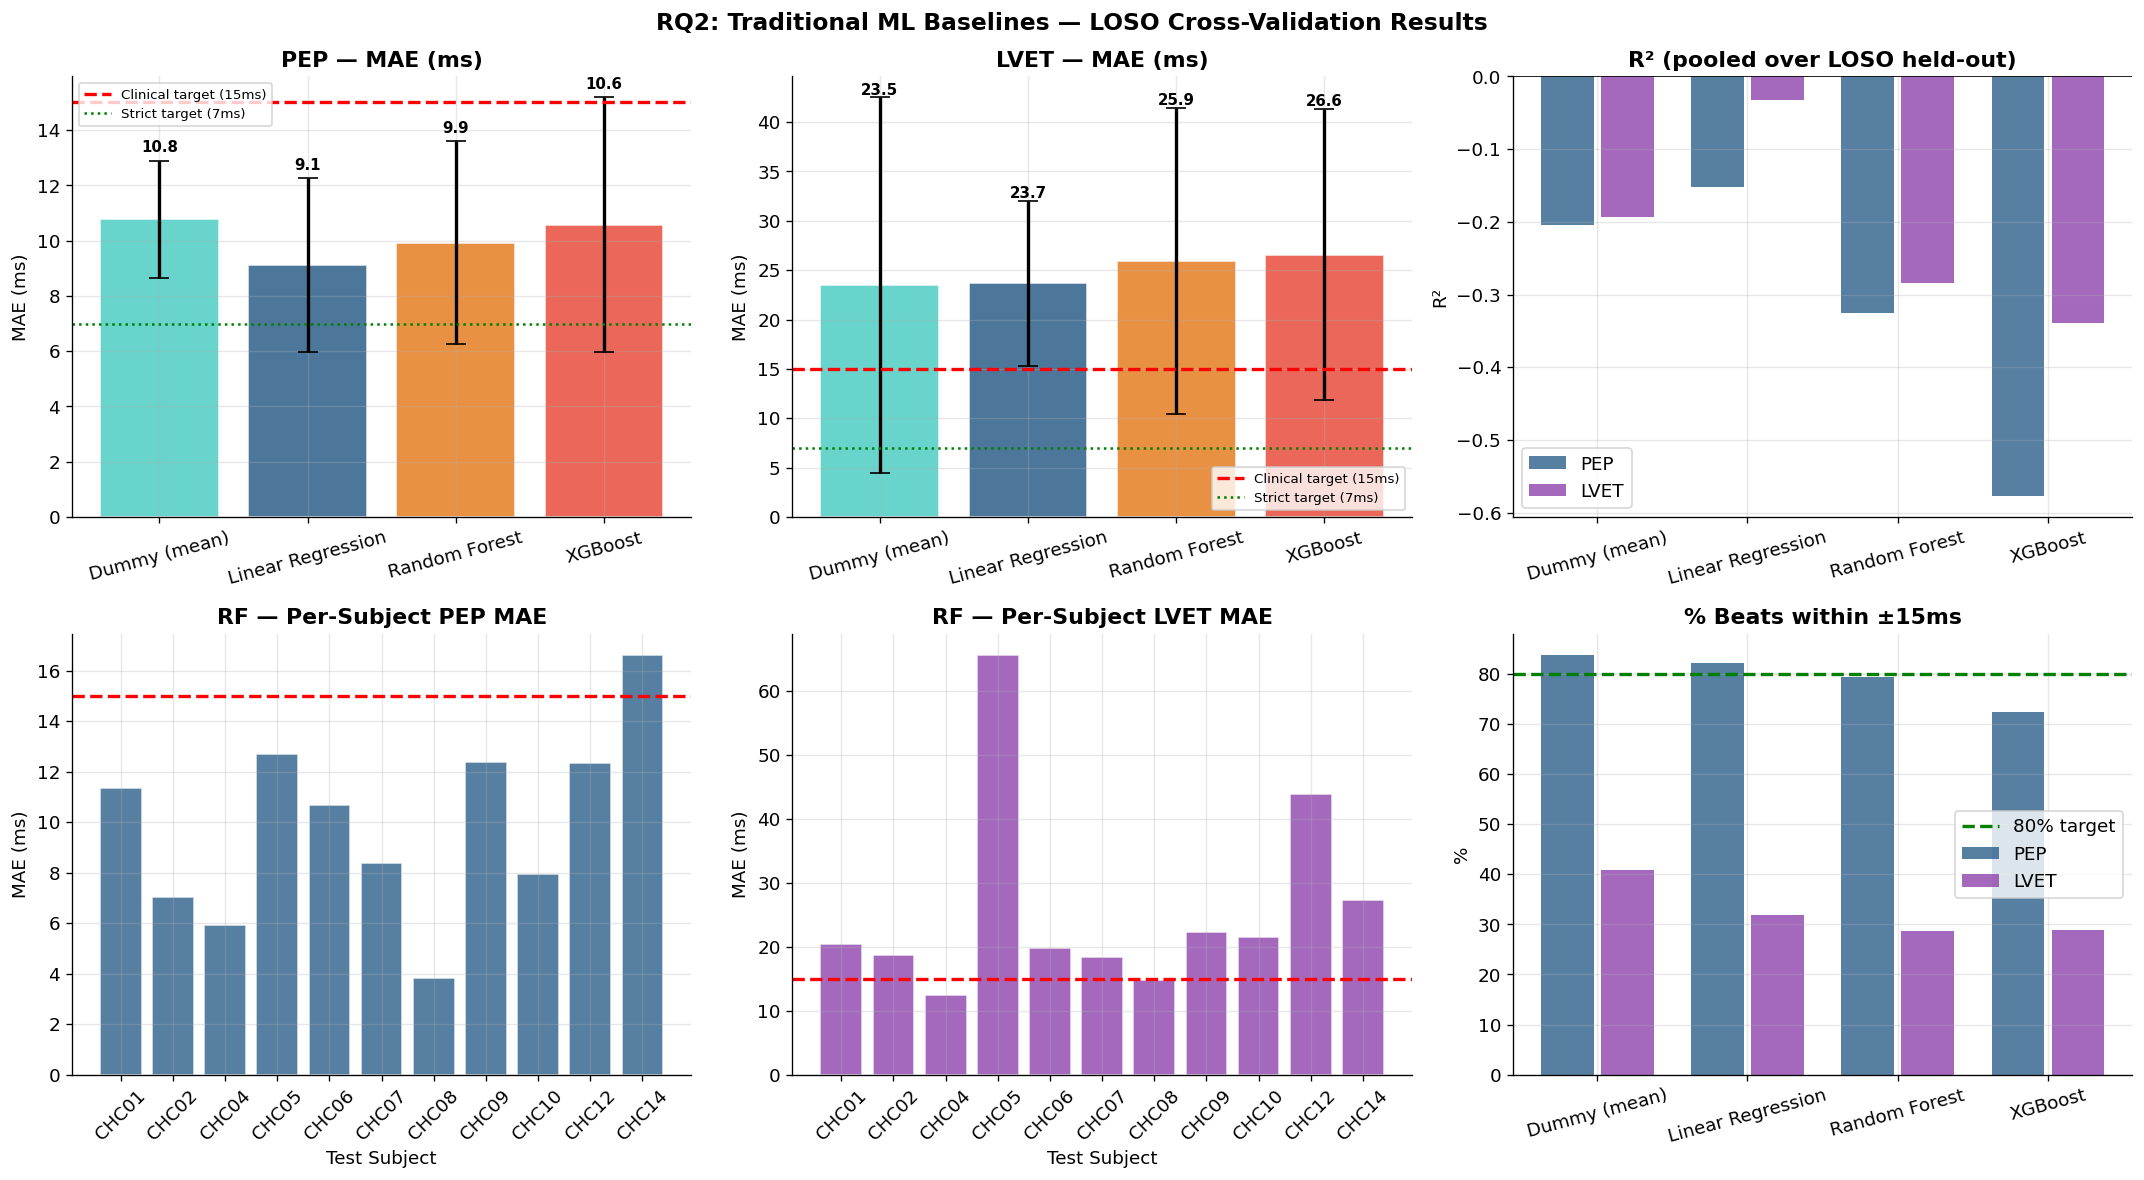

In [37]:
# Visualization: MAE comparison + per-subject fold variability
model_names = list(models_agg.keys())
n_models = len(model_names)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('RQ2: Traditional ML Baselines — LOSO Cross-Validation Results',
             fontsize=14, fontweight='bold')

colors = ['#4ECDC4', '#2C5F8A', '#E67E22', '#E74C3C']


# MAE bar chart — PEP
mae_pep  = [models_agg[m][0]['mae_mean'] for m in model_names]
mae_pep_std = [models_agg[m][0]['mae_std']  for m in model_names]
axes[0,0].bar(model_names, mae_pep, yerr=mae_pep_std, color=colors[:n_models],
              alpha=0.85, edgecolor='white', error_kw={'capsize':6,'linewidth':2})
axes[0,0].axhline(15, color='red', linewidth=2, linestyle='--', label='Clinical target (15ms)')
axes[0,0].axhline(7,  color='green', linewidth=1.5, linestyle=':', label='Strict target (7ms)')
axes[0,0].set_title('PEP — MAE (ms)', fontweight='bold')
axes[0,0].set_ylabel('MAE (ms)')
axes[0,0].tick_params(axis='x', rotation=15)
axes[0,0].legend(fontsize=8)
for i, (v, e) in enumerate(zip(mae_pep, mae_pep_std)):
    axes[0,0].text(i, v + e + 0.3, f'{v:.1f}', ha='center', fontsize=9, fontweight='bold')

# MAE bar chart — LVET
mae_lvet     = [models_agg[m][1]['mae_mean'] for m in model_names]
mae_lvet_std = [models_agg[m][1]['mae_std']  for m in model_names]
axes[0,1].bar(model_names, mae_lvet, yerr=mae_lvet_std, color=colors[:n_models],
              alpha=0.85, edgecolor='white', error_kw={'capsize':6,'linewidth':2})
axes[0,1].axhline(15, color='red', linewidth=2, linestyle='--', label='Clinical target (15ms)')
axes[0,1].axhline(7,  color='green', linewidth=1.5, linestyle=':', label='Strict target (7ms)')
axes[0,1].set_title('LVET — MAE (ms)', fontweight='bold')
axes[0,1].set_ylabel('MAE (ms)')
axes[0,1].tick_params(axis='x', rotation=15)
axes[0,1].legend(fontsize=8)
for i, (v, e) in enumerate(zip(mae_lvet, mae_lvet_std)):
    axes[0,1].text(i, v + e + 0.3, f'{v:.1f}', ha='center', fontsize=9, fontweight='bold')

# R² comparison — pooled over all LOSO held-out predictions (not per-fold mean)
r2_pep  = [models_agg[m][0]['r2_pooled'] for m in model_names]
r2_lvet = [models_agg[m][1]['r2_pooled'] for m in model_names]
x_ = np.arange(n_models)
axes[0,2].bar(x_-0.2, r2_pep,  0.35, color='#2C5F8A', alpha=0.8, label='PEP')
axes[0,2].bar(x_+0.2, r2_lvet, 0.35, color='#8E44AD', alpha=0.8, label='LVET')
axes[0,2].axhline(0, color='black', linewidth=1)
axes[0,2].set_xticks(list(x_))
axes[0,2].set_xticklabels(model_names, rotation=15)
axes[0,2].set_title('R² (pooled over LOSO held-out)', fontweight='bold')
axes[0,2].set_ylabel('R²')
axes[0,2].legend()

# Per-subject fold MAE — best model (RF)
axes[1,0].bar(rf_folds_pep['subject'], rf_folds_pep['mae_ms'],
              color='#2C5F8A', alpha=0.8, edgecolor='white')
axes[1,0].axhline(15, color='red', linewidth=2, linestyle='--')
axes[1,0].set_title('RF — Per-Subject PEP MAE', fontweight='bold')
axes[1,0].set_xlabel('Test Subject')
axes[1,0].set_ylabel('MAE (ms)')
axes[1,0].tick_params(axis='x', rotation=45)

axes[1,1].bar(rf_folds_lvet['subject'], rf_folds_lvet['mae_ms'],
              color='#8E44AD', alpha=0.8, edgecolor='white')
axes[1,1].axhline(15, color='red', linewidth=2, linestyle='--')
axes[1,1].set_title('RF — Per-Subject LVET MAE', fontweight='bold')
axes[1,1].set_xlabel('Test Subject')
axes[1,1].set_ylabel('MAE (ms)')
axes[1,1].tick_params(axis='x', rotation=45)

# Clinical acceptance rate comparison
within_15_pep  = [models_agg[m][0]['within_15ms_mean'] for m in model_names]
within_15_lvet = [models_agg[m][1]['within_15ms_mean'] for m in model_names]
axes[1,2].bar(x_-0.2, within_15_pep,  0.35, color='#2C5F8A', alpha=0.8, label='PEP')
axes[1,2].bar(x_+0.2, within_15_lvet, 0.35, color='#8E44AD', alpha=0.8, label='LVET')
axes[1,2].axhline(80, color='green', linewidth=2, linestyle='--', label='80% target')
axes[1,2].set_xticks(list(x_))
axes[1,2].set_xticklabels(model_names, rotation=15)
axes[1,2].set_title('% Beats within ±15ms', fontweight='bold')
axes[1,2].set_ylabel('%')
axes[1,2].legend()

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/rq2_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Bland-Altman Analysis — Best ML Model

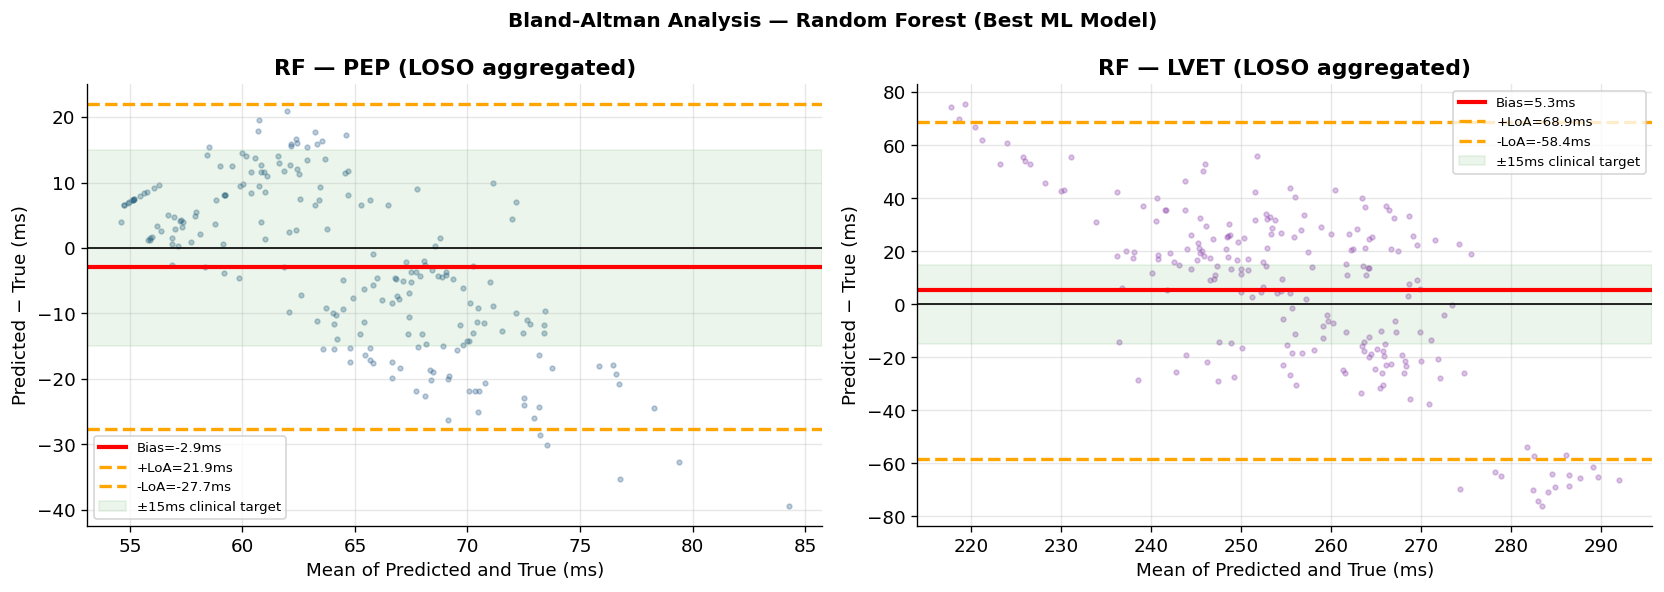

In [38]:
def bland_altman_plot(ax, pred, true, title, color='steelblue'):
    diff = pred - true
    mean = (pred + true) / 2
    md   = np.mean(diff)
    sd   = np.std(diff)
    idx  = np.random.choice(len(diff), min(1500, len(diff)), replace=False)
    ax.scatter(mean[idx], diff[idx], alpha=0.3, s=8, color=color)
    ax.axhline(md,         color='red',    linewidth=2.5, label=f'Bias={md:.1f}ms')
    ax.axhline(md+1.96*sd, color='orange', linewidth=2,   linestyle='--', label=f'+LoA={md+1.96*sd:.1f}ms')
    ax.axhline(md-1.96*sd, color='orange', linewidth=2,   linestyle='--', label=f'-LoA={md-1.96*sd:.1f}ms')
    ax.axhline(0,          color='black',  linewidth=1)
    ax.axhspan(-15, 15,    alpha=0.08, color='green', label='±15ms clinical target')
    ax.set_xlabel('Mean of Predicted and True (ms)')
    ax.set_ylabel('Predicted − True (ms)')
    ax.set_title(title, fontweight='bold')
    ax.legend(fontsize=8)
    return md, sd

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Bland-Altman Analysis — Random Forest (Best ML Model)', fontsize=12, fontweight='bold')

bland_altman_plot(axes[0], rf_agg_pep['all_preds'],  rf_agg_pep['all_true'],
                  'RF — PEP (LOSO aggregated)', '#2C5F8A')
bland_altman_plot(axes[1], rf_agg_lvet['all_preds'], rf_agg_lvet['all_true'],
                  'RF — LVET (LOSO aggregated)', '#8E44AD')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/rq2_bland_altman_rf.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. SHAP Analysis — Feature Importance and Interpretability
SHAP (SHapley Additive exPlanations) tells us which features drive each prediction.
This answers part of RQ6 for the ML models.

Computing SHAP values (this may take 30-60s)...


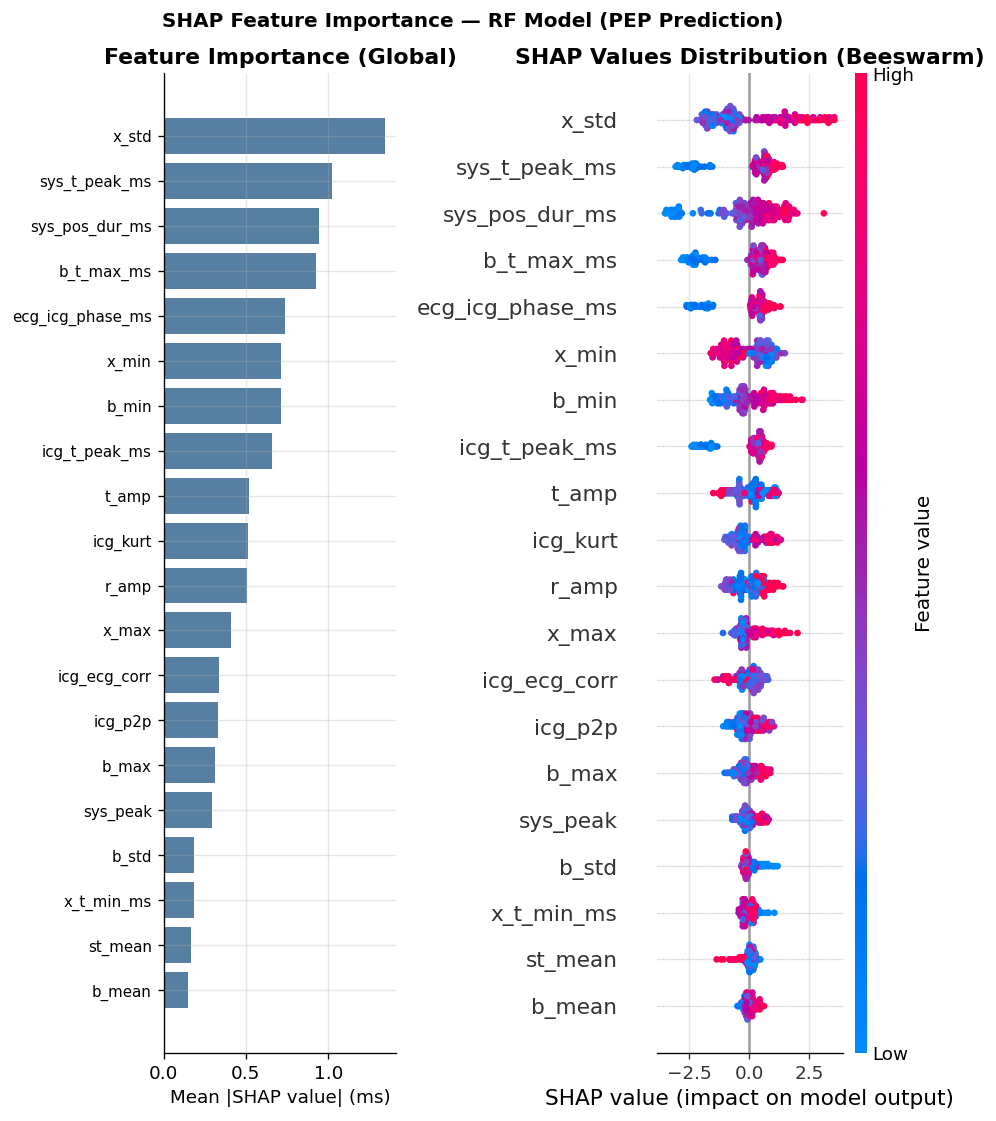


Top 5 most important features for PEP prediction:
  1. x_std: 1.3461 ms mean |SHAP|
  2. sys_t_peak_ms: 1.0233 ms mean |SHAP|
  3. sys_pos_dur_ms: 0.9460 ms mean |SHAP|
  4. b_t_max_ms: 0.9265 ms mean |SHAP|
  5. ecg_icg_phase_ms: 0.7393 ms mean |SHAP|


In [39]:
if HAS_SHAP:
    # Train final RF on all train+val data
    sc_final = StandardScaler()
    X_all_scaled = sc_final.fit_transform(X_all)
    rf_final = RandomForestRegressor(**best_rf_params, random_state=42, n_jobs=-1)
    rf_final.fit(X_all_scaled, y_pep)

    # SHAP values
    print('Computing SHAP values (this may take 30-60s)...')
    explainer = shap.TreeExplainer(rf_final)
    # Sample for speed
    sample_idx = np.random.choice(len(X_all_scaled), min(500, len(X_all_scaled)), replace=False)
    shap_values = explainer.shap_values(X_all_scaled[sample_idx])

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
    fig.suptitle('SHAP Feature Importance — RF Model (PEP Prediction)', fontsize=12, fontweight='bold')

    # Mean |SHAP| bar plot
    mean_shap = np.abs(shap_values).mean(axis=0)
    sorted_idx = np.argsort(mean_shap)[::-1]
    top_n = min(20, len(feat_names))
    top_idx   = sorted_idx[:top_n][::-1]
    top_names = [feat_names[i] for i in top_idx]
    top_vals  = mean_shap[top_idx]

    axes[0].barh(range(top_n), top_vals, color='#2C5F8A', alpha=0.8)
    axes[0].set_yticks(range(top_n))
    axes[0].set_yticklabels(top_names, fontsize=9)
    axes[0].set_xlabel('Mean |SHAP value| (ms)')
    axes[0].set_title('Feature Importance (Global)', fontweight='bold')

    # SHAP beeswarm
    plt.sca(axes[1])
    shap.summary_plot(shap_values[:, top_idx[::-1]], X_all_scaled[sample_idx][:, top_idx[::-1]],
                      feature_names=top_names[::-1], show=False, max_display=top_n)
    axes[1].set_title('SHAP Values Distribution (Beeswarm)', fontweight='bold')

    plt.tight_layout()
    plt.savefig(f'{RESULTS_DIR}/figures/rq2_shap_analysis.png', dpi=150, bbox_inches='tight')
    plt.show()

    print('\nTop 5 most important features for PEP prediction:')
    for i, (name, val) in enumerate(zip([feat_names[i] for i in sorted_idx[:5]], mean_shap[sorted_idx[:5]])):
        print(f'  {i+1}. {name}: {val:.4f} ms mean |SHAP|')
else:
    print('SHAP not available. Install with: pip install shap')

In [40]:
import pickle

# Save best models for use in later notebooks
sc_save = StandardScaler().fit(X_all)
rf_pep_final  = RandomForestRegressor(**best_rf_params, random_state=42, n_jobs=-1)
rf_lvet_final = RandomForestRegressor(**best_rf_params, random_state=42, n_jobs=-1)
rf_pep_final.fit(sc_save.transform(X_all), y_pep)
rf_lvet_final.fit(sc_save.transform(X_all), y_lvet)

with open(f'{RESULTS_DIR}/rf_pep_model.pkl',  'wb') as f: pickle.dump(rf_pep_final, f)
with open(f'{RESULTS_DIR}/rf_lvet_model.pkl', 'wb') as f: pickle.dump(rf_lvet_final, f)
with open(f'{RESULTS_DIR}/scaler.pkl',         'wb') as f: pickle.dump(sc_save, f)

print('✅ Models saved.')
print(f'\n=== RQ2 CONCLUSION ===')
best_mae = min(rf_agg_pep['mae_mean'], xgb_agg_pep['mae_mean'] if HAS_XGB and xgb_agg_pep else 999)
print(f'Best ML model PEP MAE:  {best_mae:.1f}ms')
print(f'Clinical target:        15ms')
if best_mae < 15:
    print('→ Best ML MEETS clinical target. Deep learning must do better.')
else:
    print('→ ML FAILS clinical target. Deep learning (RQ3–RQ5) is needed.')
print('\nNEXT: Notebook 06 — RQ3 LSTM/CNN-LSTM Deep Learning')

✅ Models saved.

=== RQ2 CONCLUSION ===
Best ML model PEP MAE:  9.9ms
Clinical target:        15ms
→ Best ML MEETS clinical target. Deep learning must do better.

NEXT: Notebook 06 — RQ3 LSTM/CNN-LSTM Deep Learning
